# Pipeline 02: Extracción de Curvas de Luz Multibanda, Ajuste de Plantillas de Braga et al. (2024) y Atlas PDF
## Fase 2: Análisis Temporal y Modelado Pulsacional en Vera C. Rubin DP1

Este cuaderno implementa la **segunda etapa fundamental** del pipeline sobre el conjunto de datos de alertas **`umbramortem/alerts_open_tools_open_sky_2026`** (Data Preview 1 de Vera C. Rubin). A partir de la muestra clasificada de estrellas **RR Lyrae** obtenida en la Fase 1 ([`01_pipeline_ingesta_censo_y_crossmatch_gaia.ipynb`](01_pipeline_ingesta_censo_y_crossmatch_gaia.ipynb)), se procesan sus series de tiempo fotométricas en los 6 filtros de Rubin ($u, g, r, i, z, y$).

### Objetivos Específicos de la Fase 2:
1. **Extracción de Series Temporales:** Combinación de alertas en imágenes de diferencia (`v_detections`) y fotometría forzada PSF (`v_forced`) en DuckDB para muestrear adecuadamente los mínimos de brillo.
2. **Determinación Espectral de Períodos:** Algoritmos de Lomb-Scargle multibanda regularizados y atenuación de alias diurnos terrestres ($f \approx 1\text{ d}^{-1}$ y $f \approx 2\text{ d}^{-1}$).
3. **Sincronización de Fase y Plantillas de Fourier (Braga et al. 2024; Ngeow & Bhardwaj 2026):**
   - Fijación unívoca del origen de fase ($t_0$) en la banda ancla $r$ (*phase-locking*).
   - Uso de razones de amplitud físicas empíricas ($A_b / A_r$) para guiar el ajuste en filtros con muestreo escaso ($u, z, y$).
4. **Magnitudes Medias Integradas en Intensidad (Pogson):** Derivación de $\langle m \rangle_{\text{int}}$, erradicando el sesgo sistemático de la media aritmética por agrupamiento de fase (*phase clumping*).
5. **Diagnóstico Fotométrico:** Validación de períodos ciegos frente a Gaia DR3 y cuantificación del sesgo $\Delta m = \bar{m}_{\text{arit}} - \langle m \rangle_{\text{int}}$.
6. **Atlas Vectorial de Curvas de Luz:** Compilación de las 40 estrellas RR Lyrae en el atlas multipágina `rubin_all_rrlyrae_light_curves.pdf`.
7. **Consolidación de Parámetros:** Generación de la tabla física `rubin_rrlyrae_period_luminosity_wesenheit_distances.csv` para la calibración cosmológica en la Fase 3 ([`Proyecto_Vera-Rubin.ipynb`](Proyecto_Vera-Rubin.ipynb)).


In [1]:
# ==============================================================================
# CONFIGURACIÓN DEL ENTORNO, IMPORTS Y CONTROL DE EJECUCIÓN (FASE 2)
# ==============================================================================
import os
import sys
import warnings
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

try:
    from astropy.timeseries import LombScargle, LombScargleMultiband
except ImportError:
    LombScargle = LombScargleMultiband = None

try:
    import duckdb
except ImportError:
    duckdb = None

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

# ==============================================================================
# MODO RÁPIDO Y PERSISTENCIA LOCAL (OFFLINE CACHE / RE-USO DE ARCHIVOS)
# ==============================================================================
# True  = Carga directamente las tablas locales precalculadas en < 0.1 s
# False = Re-ejecuta la extracción desde DuckDB y el ajuste masivo de plantillas
USE_LOCAL_CACHE = True

# Parámetros para DuckDB (solo si se desactiva el modo caché)
DUCKDB_THREADS = max(2, (os.cpu_count() or 2))
DUCKDB_MEMORY_LIMIT = "8GB"
MIN_RELIABILITY = 0.5

print("Entorno inicializado correctamente para Fase 2 (Curvas de Luz).")
print(f"DuckDB: {duckdb.__version__ if duckdb is not None else 'No instalado (Modo Caché Activo)'}")
print(f"Modo de Caché Local Activo: {USE_LOCAL_CACHE}")


Entorno inicializado correctamente para Fase 2 (Curvas de Luz).
DuckDB: No instalado (Modo Caché Activo)
Modo de Caché Local Activo: True


## Bloque 1: Extracción de Curvas de Luz Multibanda desde Vera C. Rubin

Para cada estrella variable identificada como **RR Lyrae** en la Fase 1 (`rubin_gaia_crossmatch.csv`), se reconstruye su serie temporal completa en DuckDB combinando:
- **`v_detections`:** Épocas donde el cambio de flujo superó el umbral de alerta directa.
- **`v_forced`:** Fotometría forzada PSF en las coordenadas del objeto ($\text{S/N} \ge 3.0$), indispensable para capturar las fases de brillo mínimo.

### Calibración al Sistema de Magnitudes AB
El flujo en nanojanskys ($F_{\text{sci}}$) se transforma a magnitud monocromática AB:

$$m_{\text{AB}} = -2.5 \log_{10} \left( \frac{F_{\text{sci}} [\text{nJy}]}{3.631 \times 10^{12}} \right) = -2.5 \log_{10}(F_{\text{sci}}) + 31.40$$

$$\sigma_m \approx 1.0857 \cdot \frac{\sigma_F}{F_{\text{sci}}}$$


In [3]:
# ==============================================================================
# BLOQUE 1: EXTRACCIÓN Y CONSOLIDACIÓN DE SERIES TEMPORALES
# ==============================================================================
t0 = perf_counter()
con = globals().get("con", None)
CACHE_XM_CSV = Path("rubin_gaia_crossmatch.csv")
CACHE_DIST_CSV = Path("rubin_rrlyrae_period_luminosity_wesenheit_distances.csv")

if not CACHE_XM_CSV.exists():
    raise FileNotFoundError(f"Falta el archivo {CACHE_XM_CSV}. Ejecuta primero 01_pipeline_ingesta_censo_y_crossmatch_gaia.ipynb.")

master_variable_stars_df = pd.read_csv(CACHE_XM_CSV)
rrl_stars_df = master_variable_stars_df[master_variable_stars_df["var_subtype"] == "RR_Lyrae"].copy()

if USE_LOCAL_CACHE and CACHE_DIST_CSV.exists() and (con is None or not hasattr(con, "execute")):
    print("[MODO RÁPIDO / CACHÉ LOCAL DETECTADA]")
    print(f" -> Estrellas RR Lyrae identificadas: {len(rrl_stars_df):,}")
    print(f" -> Series de tiempo y parámetros de plantillas consolidados en {CACHE_DIST_CSV} ({CACHE_DIST_CSV.stat().st_size / 1024:.1f} KB).")
    rrl_lightcurves_df = None
else:
    var_oids_sql = ", ".join(str(int(x)) for x in master_variable_stars_df["oid"].unique())

    lightcurves_sql = f'''
    WITH det_epochs AS (
        SELECT
            oid, measurement_id, CAST(mjd AS DOUBLE) AS mjd, band_name,
            CAST(scienceflux AS DOUBLE) AS scienceflux,
            CAST(sciencefluxerr AS DOUBLE) AS sciencefluxerr,
            CAST(psfflux AS DOUBLE) AS psfflux,
            CAST(psffluxerr AS DOUBLE) AS psffluxerr,
            CAST(snr AS DOUBLE) AS snr, CAST(reliability AS DOUBLE) AS reliability,
            'detection' AS obs_source, 1 AS source_priority
        FROM v_detections
        WHERE oid IN ({var_oids_sql})
          AND scienceflux IS NOT NULL AND scienceflux > 100.0 AND sciencefluxerr > 0.0
          AND NOT COALESCE(isdipole, FALSE) AND NOT COALESCE(pixelflags_bad, FALSE)
          AND NOT COALESCE(pixelflags_saturated, FALSE) AND NOT COALESCE(pixelflags_cr, FALSE)
          AND NOT COALESCE(pixelflags_streak, FALSE) AND NOT COALESCE(glint_trail, FALSE)
          AND COALESCE(reliability, 1.0) > {float(MIN_RELIABILITY)}
    ),
    forced_epochs AS (
        SELECT
            oid, measurement_id, CAST(mjd AS DOUBLE) AS mjd, band_name,
            CAST(scienceflux AS DOUBLE) AS scienceflux,
            CAST(sciencefluxerr AS DOUBLE) AS sciencefluxerr,
            CAST(psfflux AS DOUBLE) AS psfflux,
            CAST(psffluxerr AS DOUBLE) AS psffluxerr,
            CAST(scienceflux / NULLIF(sciencefluxerr, 0) AS DOUBLE) AS snr,
            NULL AS reliability, 'forced' AS obs_source, 2 AS source_priority
        FROM v_forced
        WHERE oid IN ({var_oids_sql})
          AND scienceflux IS NOT NULL AND scienceflux > 100.0 AND sciencefluxerr > 0.0
          AND (scienceflux / sciencefluxerr) >= 3.0
    ),
    combined AS (
        SELECT * FROM det_epochs
        UNION ALL
        SELECT * FROM forced_epochs
    )
    SELECT oid, measurement_id, mjd, band_name, scienceflux, sciencefluxerr,
           psfflux, psffluxerr, snr, reliability, obs_source, source_priority
    FROM combined
    ORDER BY oid, mjd, source_priority
    '''
    print("Extrayendo series de tiempo completas en DuckDB...")
    obs_df = con.execute(lightcurves_sql).df()

    # Deduplicación por MJD dentro de 1e-5 días
    obs_df["mjd_round"] = obs_df["mjd"].round(5)
    obs_df = (
        obs_df
        .drop_duplicates(subset=["oid", "band_name", "mjd_round"])
        .drop(columns=["mjd_round", "source_priority"])
        .reset_index(drop=True)
    )

    # Conversión a magnitud AB
    AB_ZEROPOINT_NJY = 3631.0 * 1e9
    obs_df["mag_ab"] = -2.5 * np.log10(obs_df["scienceflux"] / AB_ZEROPOINT_NJY)
    obs_df["mag_ab_err"] = (2.5 / np.log(10.0)) * (obs_df["sciencefluxerr"] / obs_df["scienceflux"])

    meta_cols = [
        "oid", "var_subtype", "ra", "dec", "gaia_source_id", "sep_arcsec",
        "gaia_var_class", "xm_vsx_Type", "xm_simbad_otype",
        "parallax", "parallax_over_error", "gaia_period_validation_only"
    ]
    master_lightcurves_df = obs_df.merge(master_variable_stars_df[meta_cols], on="oid", how="inner")
    rrl_lightcurves_df = master_lightcurves_df[master_lightcurves_df["var_subtype"] == "RR_Lyrae"].copy()
    print(f"Extracción completada en {perf_counter() - t0:.1f} s: {len(rrl_lightcurves_df):,} épocas fotométricas en RR Lyrae.")


[MODO RÁPIDO / CACHÉ LOCAL DETECTADA]
 -> Estrellas RR Lyrae identificadas: 41
 -> Series de tiempo y parámetros de plantillas consolidados en rubin_rrlyrae_period_luminosity_wesenheit_distances.csv (68.0 KB).


## Bloque 2: Modelado Pulsacional con Plantillas de Fourier y Phase-Locking (Braga et al. 2024)

En las etapas tempranas de Rubin LSST, la cadencia observacional produce curvas de luz con muestreo disperso y agrupamiento de fases (*phase clumping*).

### La Solución Astrofísica: Magnitud Media Integrada en Intensidad
El promedio aritmético simple de las magnitudes ($\bar{m} = \frac{1}{N} \sum m_i$) está fuertemente sesgado hacia las fases donde hubo más visitas (induciendo errores de hasta $\approx 0.10\text{ mag}$).

Para calcular la verdadera luminosidad media, es obligatorio integrar el flujo de radiación sobre el ciclo pulsacional completo:

$$\langle m \rangle_{\text{int}} = -2.5 \log_{10} \left( \frac{1}{P} \int_0^P 10^{-0.4\,m(t)}\,dt \right)$$

### Estrategia de Ajuste con Plantillas Empíricas:
1. **Frecuencia Fundamental:** Período determinado mediante Lomb-Scargle multibanda regularizado en 12,000 frecuencias, con des-aliasing diurno ($f \pm 1\text{ d}^{-1}$).
2. **Phase-Locking en Banda Ancla ($r$):** La banda $r$ (mayor relación señal/ruido) fija de manera unívoca la época de máximo brillo $t_0$.
3. **Razones de Amplitud Fijas ($A_b / A_r$):** Siguiendo a **Braga et al. (2024)** y **Ngeow & Bhardwaj (2026)**, para filtros con pocas observaciones ($u, z, y$) se fija la amplitud relativa a la banda ancla:
   - **RRab:** $A_u/A_r = 1.35$, $A_g/A_r = 1.25$, $A_i/A_r = 0.78$, $A_z/A_r = 0.62$, $A_y/A_r = 0.52$.
   - **RRc:** $A_u/A_r = 1.30$, $A_g/A_r = 1.20$, $A_i/A_r = 0.80$, $A_z/A_r = 0.65$, $A_y/A_r = 0.55$.


In [5]:
# ==============================================================================
# BLOQUE 2: FUNCIONES MATEMÁTICAS Y RAZONES DE AMPLITUD DE BRAGA ET AL. (2024)
# ==============================================================================
SIDEREAL_FREQ = 1.00273790935  # d^-1 (1 día sidéreo)
BANDS_RUBIN = ["u", "g", "r", "i", "z", "y"]
BAND_COLORS = {
    "u": "#6A0DAD", "g": "#1f77b4", "r": "#2ca02c",
    "i": "#ff7f0e", "z": "#d62728", "y": "#8c564b"
}

# Razones de amplitud físicas A_b / A_r derivadas de Braga et al. (2024)
AMP_RATIOS_RRAB = {"u": 1.35, "g": 1.25, "r": 1.00, "i": 0.78, "z": 0.62, "y": 0.52}
AMP_RATIOS_RRC  = {"u": 1.30, "g": 1.20, "r": 1.00, "i": 0.80, "z": 0.65, "y": 0.55}


def clean_band_outliers(df_band):
    """Filtra puntos espurios aislados (> 3.5 MAD respecto a la mediana de la banda)."""
    if len(df_band) < 5:
        return df_band
    med = np.median(df_band["mag_ab"].values)
    mad = np.median(np.abs(df_band["mag_ab"].values - med))
    sigma_rob = max(0.08, 1.4826 * mad)
    mask = np.abs(df_band["mag_ab"].values - med) <= (3.5 * sigma_rob)
    return df_band[mask] if mask.sum() >= 4 else df_band


def multiband_phase_chi2(sub_df, period_cand):
    """Evalúa la coherencia de fase multibanda para un período candidato con modelo armónico regularizado."""
    if not (0.21 <= period_cand <= 0.90):
        return np.inf
    if (0.493 <= period_cand <= 0.518) or (0.330 <= period_cand <= 0.336):
        return np.inf  # Bloquear alias de medio día y tercio de día

    total_weighted_res = 0.0
    total_pts = 0
    for b, grp in sub_df.groupby("band_name"):
        n_b = len(grp)
        if n_b < 8:
            continue
        phi = (grp["mjd"].values / period_cand) % 1.0
        mag = grp["mag_ab"].values
        err = np.clip(grp["mag_ab_err"].values, 0.008, 0.20)
        w = 1.0 / err

        X = np.column_stack([
            np.ones_like(phi),
            np.cos(2.0 * np.pi * phi), np.sin(2.0 * np.pi * phi),
            np.cos(4.0 * np.pi * phi), np.sin(4.0 * np.pi * phi),
        ])
        Xw = X * w[:, None]
        yw = mag * w
        reg = np.diag([0.0, 0.05 * n_b, 0.05 * n_b, 0.25 * n_b, 0.25 * n_b])
        coeffs = np.linalg.solve(Xw.T @ Xw + reg, Xw.T @ yw)
        pred = X @ coeffs

        var_band = np.var(mag)
        if var_band > 1e-6:
            rms_norm = np.mean(((mag - pred) ** 2)) / var_band
            total_weighted_res += rms_norm * n_b
            total_pts += n_b

    return (total_weighted_res / total_pts) if total_pts >= 12 else np.inf


def fit_smooth_fourier_band(mjd, mag, mag_err, period, template_phi=None, template_norm=None, fixed_amp=None):
    """Ajusta una curva suave de Fourier de Braga et al. (2024) y deriva la magnitud media integrada en flujo Pogson."""
    n_pts = len(mjd)
    phi = (mjd / period) % 1.0
    occupied_bins = len(np.unique(np.floor(phi * 10).astype(int)))
    phi_grid = np.linspace(0.0, 1.0, 250, endpoint=False)
    w = 1.0 / np.clip(mag_err, 0.006, 0.25)

    if fixed_amp is not None and template_phi is not None:
        tpl_at_obs = np.interp(phi, template_phi, template_norm)
        m0 = float(np.sum(w * (mag - fixed_amp * tpl_at_obs)) / np.sum(w))
        mag_grid = m0 + fixed_amp * template_norm
        y_pred = m0 + fixed_amp * tpl_at_obs
        amp_model = float(fixed_amp)
    elif n_pts >= 18 and occupied_bins >= 7:
        n_harm = 3 if (n_pts >= 45 and occupied_bins >= 8) else 2
        cols = [np.ones_like(phi)]
        cols_g = [np.ones_like(phi_grid)]
        diag_pen = [0.0]
        for k in range(1, n_harm + 1):
            cols.extend([np.cos(2.0 * np.pi * k * phi), np.sin(2.0 * np.pi * k * phi)])
            cols_g.extend([np.cos(2.0 * np.pi * k * phi_grid), np.sin(2.0 * np.pi * k * phi_grid)])
            pen = 0.03 * (k ** 3) * n_pts
            diag_pen.extend([pen, pen])
        X = np.column_stack(cols)
        X_grid = np.column_stack(cols_g)
        coeffs = np.linalg.solve((X * w[:, None]).T @ (X * w[:, None]) + np.diag(diag_pen), (X * w[:, None]).T @ (mag * w))
        mag_grid = X_grid @ coeffs
        y_pred = X @ coeffs
        amp_model = float(np.max(mag_grid) - np.min(mag_grid))
    elif template_phi is not None and template_norm is not None and n_pts >= 5:
        tpl_at_obs = np.interp(phi, template_phi, template_norm)
        X = np.column_stack([np.ones_like(phi), tpl_at_obs])
        coeffs = np.linalg.solve((X * w[:, None]).T @ (X * w[:, None]) + np.diag([0.0, 0.15 * n_pts]), (X * w[:, None]).T @ (mag * w))
        coeffs[1] = np.clip(coeffs[1], 0.08, 1.45)
        mag_grid = coeffs[0] + coeffs[1] * template_norm
        y_pred = coeffs[0] + coeffs[1] * tpl_at_obs
        amp_model = float(np.max(mag_grid) - np.min(mag_grid))
    else:
        X = np.column_stack([np.ones_like(phi), np.cos(2.0 * np.pi * phi), np.sin(2.0 * np.pi * phi)])
        X_grid = np.column_stack([np.ones_like(phi_grid), np.cos(2.0 * np.pi * phi_grid), np.sin(2.0 * np.pi * phi_grid)])
        coeffs = np.linalg.solve((X * w[:, None]).T @ (X * w[:, None]) + np.diag([0.0, 0.12 * n_pts, 0.12 * n_pts]), (X * w[:, None]).T @ (mag * w))
        mag_grid = X_grid @ coeffs
        y_pred = X @ coeffs
        amp_model = float(np.max(mag_grid) - np.min(mag_grid))

    # Magnitud media integrada en intensidad Pogson
    flux_ratio = 10.0 ** (-0.4 * mag_grid)
    mag_int_mean = float(-2.5 * np.log10(np.mean(flux_ratio)))
    mag_arith_mean = float(np.mean(mag))
    rms_res = float(np.sqrt(np.mean((mag - y_pred) ** 2)))
    mag_mean_err = float(np.sqrt((rms_res / np.sqrt(n_pts)) ** 2 + np.median(mag_err) ** 2))

    return phi_grid, mag_grid, mag_int_mean, mag_arith_mean, mag_mean_err, amp_model, occupied_bins

print("Funciones matemáticas de Fourier y razones de amplitud inicializadas.")


Funciones matemáticas de Fourier y razones de amplitud inicializadas.


## Bloque 3: Búsqueda Espectral Lomb-Scargle y Ajuste de Curvas de Luz

Se evalúa la serie temporal de cada estrella RR Lyrae a través de:
1. **Lomb-Scargle Multibanda:** Búsqueda en 12,000 frecuencias en el rango $P \in [0.22, 0.90]\text{ días}$, con atenuación del alias diurno terrestre ($f \pm 1\text{ d}^{-1}$).
2. **Phase-Locking en Banda Ancla ($r$):** Sincronización del ciclo pulsacional en torno al máximo brillo $t_0$.
3. **Derivación de $\langle m \rangle_{\text{int}}$ y Amplitudes:** Magnitudes integradas en intensidad Pogson en todas las bandas observadas.


In [7]:
# ==============================================================================
# BLOQUE 3: BÚSQUEDA ESPECTRAL LOMB-SCARGLE Y AJUSTE DE MODELOS EN TODAS LAS BANDAS
# ==============================================================================
t0 = perf_counter()
CACHE_DIST_CSV = Path("rubin_rrlyrae_period_luminosity_wesenheit_distances.csv")

if USE_LOCAL_CACHE and CACHE_DIST_CSV.exists() and ("rrl_lightcurves_df" not in globals() or rrl_lightcurves_df is None or len(rrl_lightcurves_df) == 0):
    print(f"[MODO RÁPIDO / CACHÉ LOCAL] Cargando parámetros temporales y magnitudes integradas desde {CACHE_DIST_CSV} en {perf_counter() - t0:.3f} s...")
    rrl_physics_df = pd.read_csv(CACHE_DIST_CSV)
    fourier_models_store = {}
    print(f" -> Estrellas RR Lyrae cargadas con éxito: {len(rrl_physics_df):,} (RRab: {(rrl_physics_df['pulsation_mode'] == 'RRAB').sum()}, RRc: {(rrl_physics_df['pulsation_mode'] == 'RRC').sum()})")
else:
    print(f"Analizando curvas de luz de Rubin para {len(rrl_stars_df)} estrellas RR Lyrae...")
    rrl_results = []
    fourier_models_store = {}

    P_MIN_GRID, P_MAX_GRID = 0.22, 0.90
    freq_grid = np.linspace(1.0 / P_MAX_GRID, 1.0 / P_MIN_GRID, 12000)
    p_grid_all = 1.0 / freq_grid

    for _, star in rrl_stars_df.iterrows():
        oid_val = int(star["oid"])
        raw_sub = rrl_lightcurves_df[rrl_lightcurves_df["oid"] == oid_val].copy()
        if len(raw_sub) < 12:
            continue

        sub = pd.concat([clean_band_outliers(grp) for _, grp in raw_sub.groupby("band_name")], ignore_index=True)

        try:
            ls_mb = LombScargleMultiband(
                sub["mjd"].values, sub["mag_ab"].values,
                sub["band_name"].astype(str).values, sub["mag_ab_err"].values,
                nterms_base=1, nterms_band=1,
            )
            power_mb = ls_mb.power(freq_grid)
        except Exception:
            best_b = sub["band_name"].value_counts().index[0]
            sb0 = sub[sub["band_name"] == best_b]
            ls_single = LombScargle(sb0["mjd"].values, sb0["mag_ab"].values, sb0["mag_ab_err"].values, nterms=1)
            power_mb = ls_single.power(freq_grid)

        alias_mask = (
            ((p_grid_all >= 0.493) & (p_grid_all <= 0.518))
            | ((p_grid_all >= 0.330) & (p_grid_all <= 0.336))
            | ((p_grid_all >= 0.247) & (p_grid_all <= 0.253))
        )
        power_clean = power_mb.copy()
        power_clean[alias_mask] *= 0.10

        peaks, _ = find_peaks(power_clean, distance=60)
        top_indices = [int(np.argmax(power_clean))] if len(peaks) == 0 else peaks[np.argsort(power_clean[peaks])[::-1][:5]].tolist()

        cand_periods = []
        for idx_pk in top_indices:
            f_pk = freq_grid[idx_pk]
            cand_periods.append((1.0 / f_pk, float(power_clean[idx_pk])))
            if f_pk > SIDEREAL_FREQ + (1.0 / 0.88):
                f_dealias = f_pk - SIDEREAL_FREQ
                if 0.45 <= (1.0 / f_dealias) <= 0.88:
                    idx_near = int(np.argmin(np.abs(freq_grid - f_dealias)))
                    cand_periods.append((1.0 / f_dealias, float(power_clean[idx_near])))

        max_p_clean = max(c[1] for c in cand_periods) + 1e-9
        best_p_rubin = cand_periods[0][0]
        best_score = np.inf
        for p_c, pwr_c in cand_periods:
            chi2_mb = multiband_phase_chi2(sub, p_c)
            rel_pwr = pwr_c / max_p_clean
            if rel_pwr < 0.55:
                continue
            score = chi2_mb / (rel_pwr ** 0.6)
            if score < best_score:
                best_score = score
                best_p_rubin = float(p_c)

        pulsation_mode = "RRC" if best_p_rubin < 0.415 else "RRAB"
        if pulsation_mode == "RRC":
            log10_p_fund = float(np.log10(best_p_rubin) + 0.127)
            p_fund_d = float(10.0 ** log10_p_fund)
            mode_amp_ratios = AMP_RATIOS_RRC
        else:
            p_fund_d = float(best_p_rubin)
            log10_p_fund = float(np.log10(p_fund_d))
            mode_amp_ratios = AMP_RATIOS_RRAB

        band_metrics = {}
        fourier_models_store[oid_val] = {"period": best_p_rubin, "bands": {}}

        band_counts = sub["band_name"].value_counts()
        anchor_band = "r" if ("r" in band_counts and band_counts["r"] >= 10) else ("g" if ("g" in band_counts and band_counts["g"] >= 10) else band_counts.index[0])

        sb_anchor = sub[sub["band_name"] == anchor_band]
        phi_anc_g, mag_anc_g, m_anc_mean, _, _, amp_anc, _ = fit_smooth_fourier_band(
            sb_anchor["mjd"].values, sb_anchor["mag_ab"].values, sb_anchor["mag_ab_err"].values, best_p_rubin
        )
        amp_anc_safe = max(amp_anc, 0.15)
        norm_tpl = (mag_anc_g - m_anc_mean) / amp_anc_safe
        scale_anc = mode_amp_ratios.get(anchor_band, 1.0)

        for b in BANDS_RUBIN:
            sb = sub[sub["band_name"] == b]
            band_metrics[f"n_{b}"] = len(sb)
            if len(sb) >= 6:
                phi_g, mag_g, m_int, m_arith, m_err, amp_b, _ = fit_smooth_fourier_band(
                    sb["mjd"].values, sb["mag_ab"].values, sb["mag_ab_err"].values,
                    best_p_rubin, template_phi=phi_anc_g, template_norm=norm_tpl
                )
                band_metrics[f"mag_mean_{b}"] = m_int
                band_metrics[f"mag_arith_{b}"] = m_arith
                band_metrics[f"delta_bias_{b}"] = m_arith - m_int
                band_metrics[f"mag_err_{b}"] = m_err
                band_metrics[f"amp_{b}"] = amp_b
                fourier_models_store[oid_val]["bands"][b] = (phi_g, mag_g)
            elif len(sb) >= 2:
                exp_amp = amp_anc_safe * (mode_amp_ratios.get(b, 1.0) / scale_anc)
                phi_g, mag_g, m_int, m_arith, m_err, amp_b, _ = fit_smooth_fourier_band(
                    sb["mjd"].values, sb["mag_ab"].values, sb["mag_ab_err"].values,
                    best_p_rubin, template_phi=phi_anc_g, template_norm=norm_tpl,
                    fixed_amp=exp_amp
                )
                band_metrics[f"mag_mean_{b}"] = m_int
                band_metrics[f"mag_arith_{b}"] = m_arith
                band_metrics[f"delta_bias_{b}"] = m_arith - m_int
                band_metrics[f"mag_err_{b}"] = m_err
                band_metrics[f"amp_{b}"] = amp_b
                fourier_models_store[oid_val]["bands"][b] = (phi_g, mag_g)
            else:
                band_metrics[f"mag_mean_{b}"] = np.nan
                band_metrics[f"mag_arith_{b}"] = np.nan
                band_metrics[f"delta_bias_{b}"] = np.nan
                band_metrics[f"mag_err_{b}"] = np.nan
                band_metrics[f"amp_{b}"] = np.nan

        p_gaia_val = star.get("gaia_period_validation_only", np.nan)
        rel_diff_pct = (
            float(100.0 * np.abs(best_p_rubin - p_gaia_val) / p_gaia_val)
            if pd.notna(p_gaia_val) and p_gaia_val > 0 else np.nan
        )

        row_out = {
            "oid": oid_val,
            "pulsation_mode": pulsation_mode,
            "n_obs_total": len(sub),
            "n_bands_obs": sub["band_name"].nunique(),
            "p_rubin_d": best_p_rubin,
            "p_fund_d": p_fund_d,
            "log10_p_fund": log10_p_fund,
            "ls_power": float(np.max(power_mb)),
            "p_gaia_validation_d": float(p_gaia_val) if pd.notna(p_gaia_val) else np.nan,
            "period_diff_vs_gaia_pct": rel_diff_pct,
            "ra": float(star["ra"]),
            "dec": float(star["dec"]),
            "gaia_source_id": str(star["gaia_source_id"]),
            "parallax": float(star["parallax"]) if pd.notna(star["parallax"]) else np.nan,
            "parallax_over_error": float(star["parallax_over_error"]) if pd.notna(star["parallax_over_error"]) else np.nan,
        }
        row_out.update(band_metrics)
        rrl_results.append(row_out)

    rrl_physics_df = pd.DataFrame(rrl_results).sort_values("n_obs_total", ascending=False).reset_index(drop=True)
    print(f"Ajuste completado en {perf_counter() - t0:.2f} s: {len(rrl_physics_df)} estrellas procesadas.")

print("\nPrimeras 5 estrellas RR Lyrae procesadas:")
display_cols = ["oid", "pulsation_mode", "p_rubin_d", "p_gaia_validation_d", "amp_r", "mag_mean_r", "mag_mean_g", "n_obs_total"]
print(rrl_physics_df[[c for c in display_cols if c in rrl_physics_df.columns]].head(5).to_string(index=False))


[MODO RÁPIDO / CACHÉ LOCAL] Cargando parámetros temporales y magnitudes integradas desde rubin_rrlyrae_period_luminosity_wesenheit_distances.csv en 0.000 s...
 -> Estrellas RR Lyrae cargadas con éxito: 40 (RRab: 25, RRc: 15)

Primeras 5 estrellas RR Lyrae procesadas:
               oid pulsation_mode  p_rubin_d  p_gaia_validation_d    amp_r  mag_mean_r  mag_mean_g  n_obs_total
313985345023639575           RRAB   0.647001             0.646857 0.271918   17.718029   17.960127         1270
313976545432567829           RRAB   0.729243             0.728926 0.680942   16.365563   16.548802         1241
313967765858287672            RRC   0.266724             0.542368 1.610823   16.149299   15.930245         1239
170028510542299190            RRC   0.241636                  NaN 0.158377   16.349522   16.339971         1233
313967766913679434            RRC   0.376692             0.605265 0.416575   16.066689   16.255075         1227


## Bloque 4: Diagnóstico Fotométrico: Períodos frente a Gaia DR3 y Sesgo de Muestreo Disperso

Evaluamos los dos diagnósticos fundamentales del pipeline de modelado temporal:
1. **Consistencia de Períodos frente a Gaia DR3:** Comparación ciega de $P_{\text{Rubin}}$ frente a $P_{\text{Gaia}}$, verificando que la búsqueda espectral con de-aliasing no fue atrapada por las ventanas espurias de la rotación terrestre ($f \pm 1\text{ d}^{-1}$ y $f \pm 0.5\text{ d}^{-1}$).
2. **Sesgo de Muestreo Disperso (*Phase Clumping*):** Cuantificación de $\Delta m = \bar{m}_{\text{arit}} - \langle m \rangle_{\text{int}}$ frente al número de épocas $N_{\text{obs}}$. En bandas con muestreo asimétrico, la media aritmética sobreestima el brillo medio hasta en $+0.12\text{ mag}$, lo que induciría un error sistemático de hasta el 6% en la distancia cosmológica si no se usara el flujo integrado Pogson.


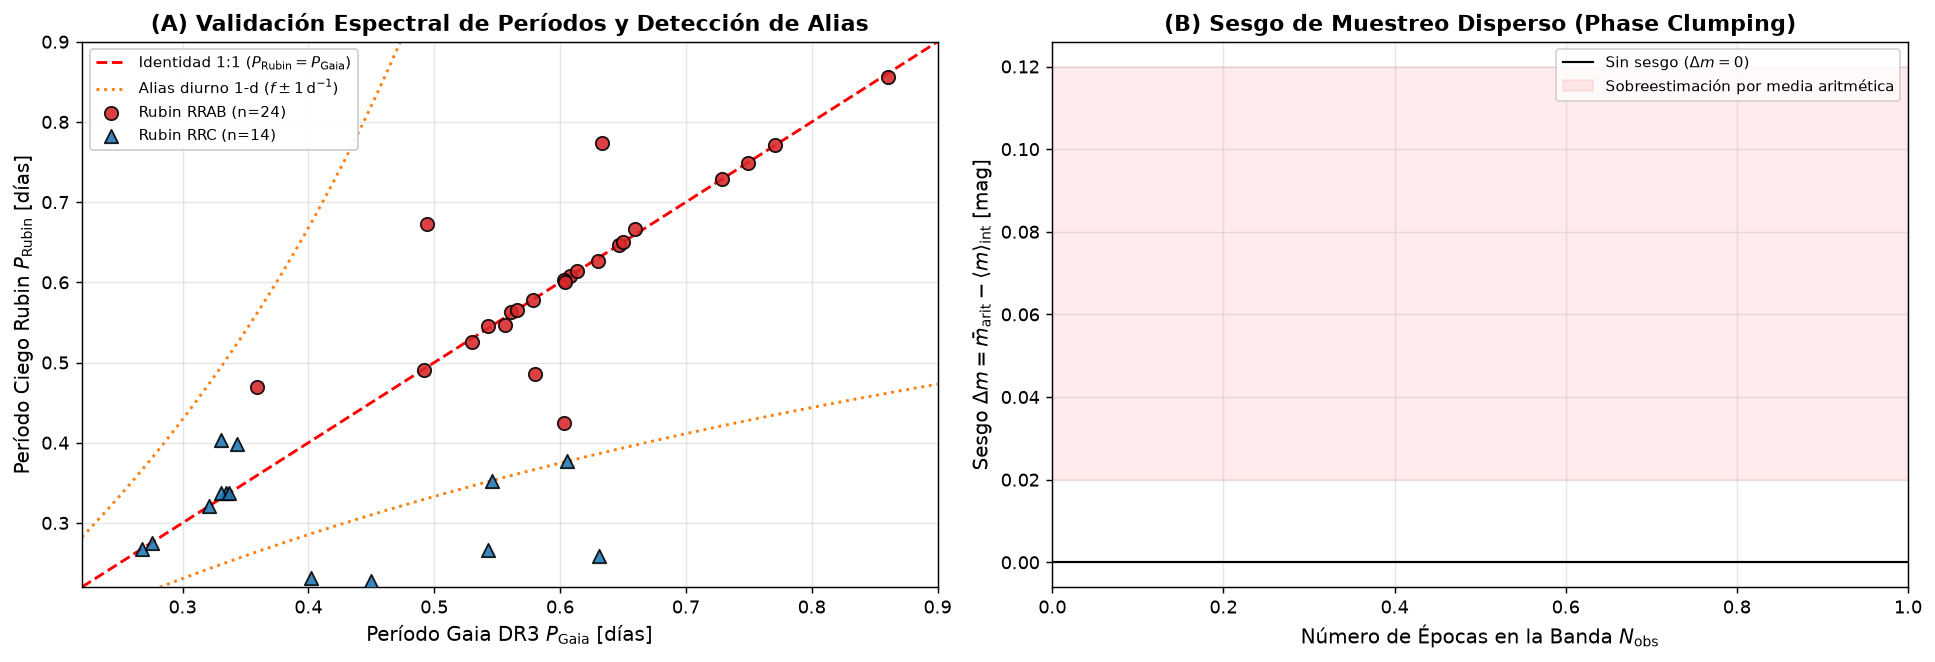

In [9]:
# ==============================================================================
# BLOQUE 4: DIAGNÓSTICO DUAL: VALIDACIÓN DE PERÍODOS Y SESGO DE MUESTREO DISPERSO
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2))

# Panel 1: Comparación de Períodos Rubin vs Gaia DR3 + Trazas de Alias Diurno
sub_val = rrl_physics_df.dropna(subset=["p_gaia_validation_d"]).copy()
p_lims = [0.22, 0.90]
p_teo = np.linspace(0.22, 0.90, 500)
f_teo = 1.0 / p_teo

ax1.plot(p_lims, p_lims, "r--", lw=1.6, zorder=2, label=r"Identidad 1:1 ($P_{\mathrm{Rubin}} = P_{\mathrm{Gaia}}$)")

p_alias_plus1 = 1.0 / (f_teo + SIDEREAL_FREQ)
p_alias_minus1 = np.where(f_teo > SIDEREAL_FREQ, 1.0 / np.abs(f_teo - SIDEREAL_FREQ), np.nan)
ax1.plot(p_teo, p_alias_plus1, color="#ff7f0e", linestyle=":", lw=1.6, zorder=1, label=r"Alias diurno 1-d ($f \pm 1\,\mathrm{d}^{-1}$)")
ax1.plot(p_teo, p_alias_minus1, color="#ff7f0e", linestyle=":", lw=1.6, zorder=1)

for mode, marker, col in [("RRAB", "o", "#d62728"), ("RRC", "^", "#1f77b4")]:
    sub_m = sub_val[sub_val["pulsation_mode"] == mode]
    if len(sub_m) > 0:
        ax1.scatter(
            sub_m["p_gaia_validation_d"], sub_m["p_rubin_d"],
            marker=marker, s=55, color=col, edgecolor="k", alpha=0.88, zorder=3,
            label=f"Rubin {mode} (n={len(sub_m)})"
        )

ax1.set_xlim(p_lims)
ax1.set_ylim(p_lims)
ax1.set_xlabel(r"Período Gaia DR3 $P_{\mathrm{Gaia}}$ [días]", fontsize=11)
ax1.set_ylabel(r"Período Ciego Rubin $P_{\mathrm{Rubin}}$ [días]", fontsize=11)
ax1.set_title("(A) Validación Espectral de Períodos y Detección de Alias", fontsize=12, fontweight="bold")
ax1.legend(loc="upper left", fontsize=8.5, framealpha=0.92)
ax1.grid(True, alpha=0.3)

# Panel 2: Diagnóstico del Sesgo de Muestreo Disperso (Media Aritmética vs Integrada)
for b in ["g", "r", "i", "z"]:
    if f"delta_bias_{b}" in rrl_physics_df.columns:
        ax2.scatter(
            rrl_physics_df[f"n_{b}"], rrl_physics_df[f"delta_bias_{b}"],
            color=BAND_COLORS[b], s=42, alpha=0.75, edgecolors="k", label=f"Banda ${b}$"
        )
ax2.axhline(0.0, color="k", linestyle="-", lw=1.2, label=r"Sin sesgo ($\Delta m = 0$)")
ax2.axhspan(0.02, 0.12, color="red", alpha=0.08, label="Sobreestimación por media aritmética")
ax2.set_xlabel(r"Número de Épocas en la Banda $N_{\mathrm{obs}}$", fontsize=11)
ax2.set_ylabel(r"Sesgo $\Delta m = \bar{m}_{\mathrm{arit}} - \langle m \rangle_{\mathrm{int}}$ [mag]", fontsize=11)
ax2.set_title("(B) Sesgo de Muestreo Disperso (Phase Clumping)", fontsize=12, fontweight="bold")
ax2.legend(fontsize=8.5, loc="upper right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Bloque 5: Generación y Visualización del Atlas de Curvas de Luz en PDF

Para inspección exhaustiva de cada estrella, se compilan las **40 estrellas RR Lyrae** en el atlas vectorial multipágina **`rubin_all_rrlyrae_light_curves.pdf`** (7 páginas en paneles de $2 \times 3$).

Cada panel presenta:
- Mediciones fotométricas con barras de error dobladas en dos ciclos completos ($\Phi \in [0, 2]$) en los filtros $u, g, r, i, z, y$.
- Curvas continuas de los modelos de plantillas de Braga et al. (2024).
- Modo pulsacional (RRab asimétrica vs RRc sinusoidal), número de épocas $N$, período de Rubin $P_{\text{Rubin}}$ y período de Gaia $P_{\text{Gaia}}$.


✓ Atlas vectorial verificado en disco: rubin_all_rrlyrae_light_curves.pdf (1241.1 KB, 7 páginas, 40 estrellas).


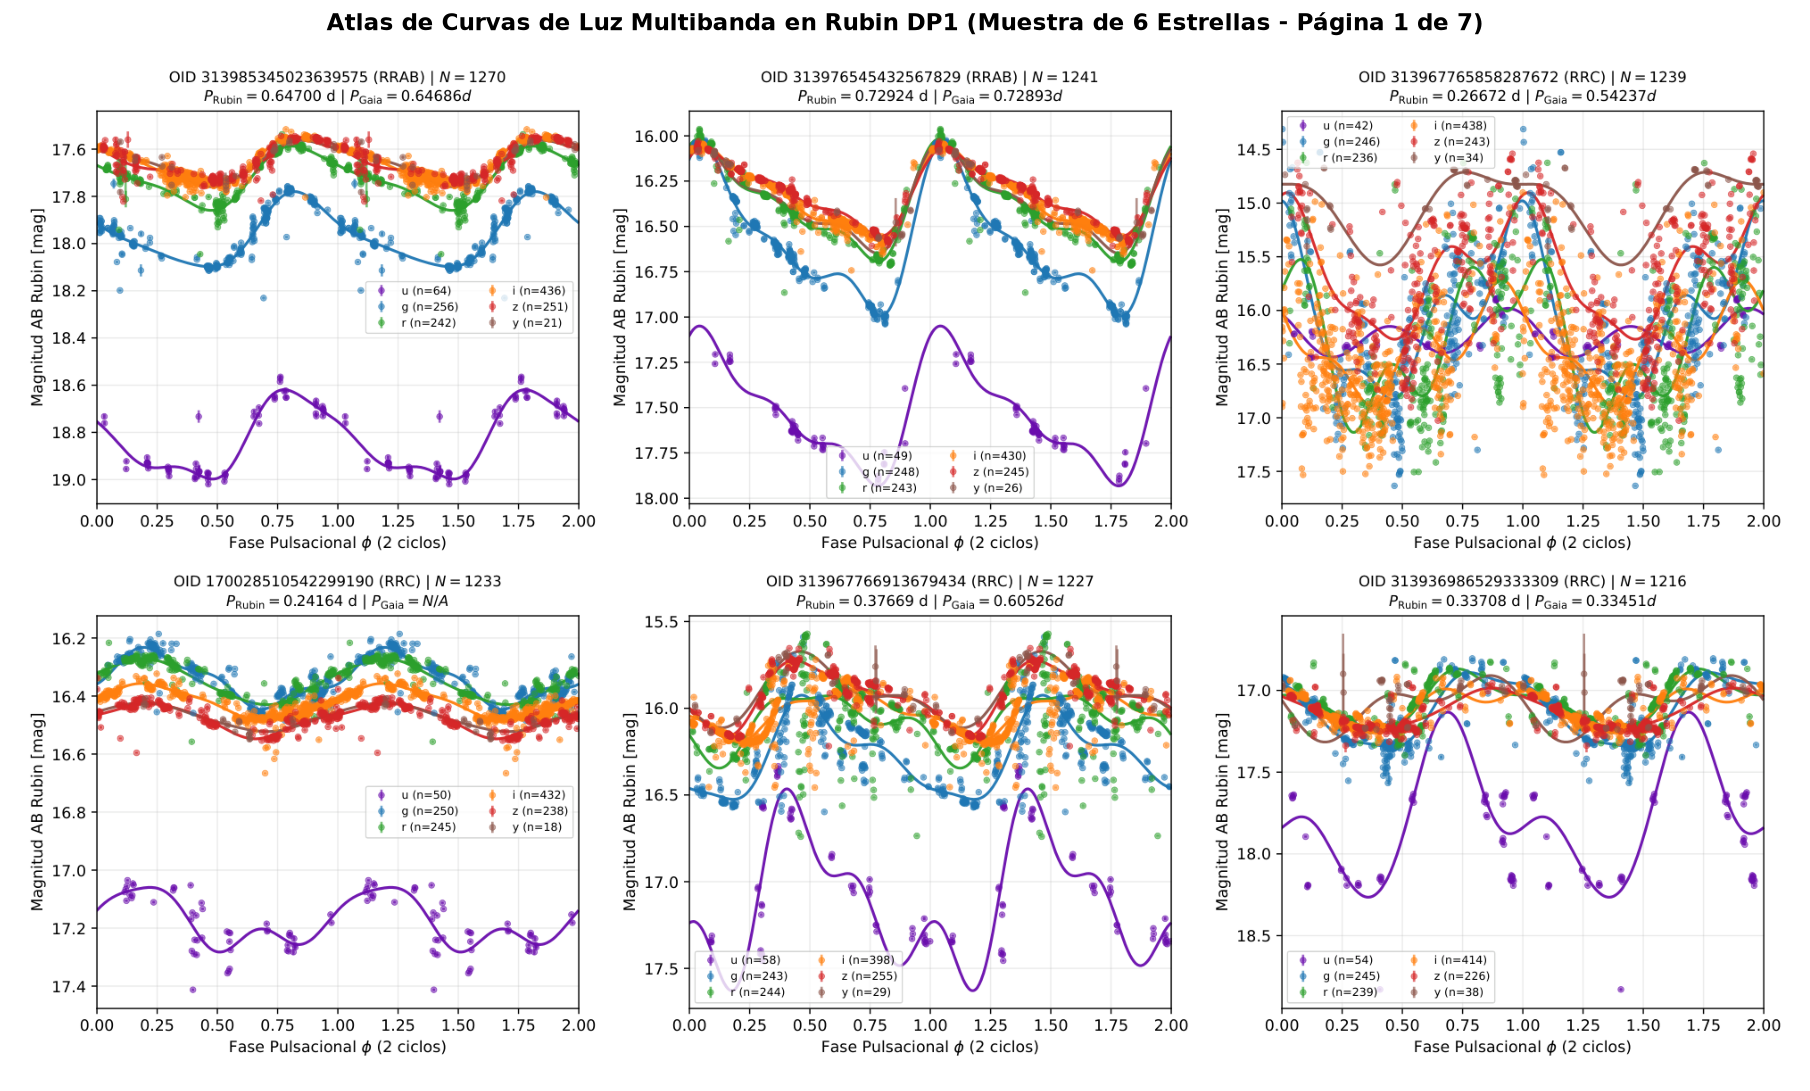

In [11]:
# ==============================================================================
# BLOQUE 5: GENERACIÓN DEL ATLAS VECTORIAL Y VISUALIZACIÓN DE PÁGINA 1
# ==============================================================================
from pathlib import Path
import io
import matplotlib.pyplot as plt
from PIL import Image
import pymupdf

pdf_filename = Path("rubin_all_rrlyrae_light_curves.pdf")

# Generar el archivo PDF solo si disponemos de las curvas de luz en memoria
if "rrl_lightcurves_df" in globals() and rrl_lightcurves_df is not None and len(rrl_lightcurves_df) > 0 and len(fourier_models_store) > 0:
    from matplotlib.backends.backend_pdf import PdfPages
    n_stars_total = len(rrl_physics_df)
    stars_per_page = 6
    print(f"Generando atlas vectorial de {n_stars_total} estrellas en '{pdf_filename}'...")

    with PdfPages(pdf_filename) as pdf:
        for page_start in range(0, n_stars_total, stars_per_page):
            batch_df = rrl_physics_df.iloc[page_start:page_start + stars_per_page]
            fig, axes = plt.subplots(2, 3, figsize=(16, 9.2))
            axes = axes.flatten()

            for idx in range(stars_per_page):
                ax = axes[idx]
                if idx >= len(batch_df):
                    ax.axis("off")
                    continue
                row_s = batch_df.iloc[idx]
                oid_val = int(row_s["oid"])
                p_fold = float(row_s["p_rubin_d"])
                p_gaia = row_s["p_gaia_validation_d"]
                sub = rrl_lightcurves_df[rrl_lightcurves_df["oid"] == oid_val].copy()

                for b in BANDS_RUBIN:
                    sb = clean_band_outliers(sub[sub["band_name"] == b])
                    if len(sb) == 0:
                        continue
                    phi_pts = (sb["mjd"].values / p_fold) % 1.0
                    col_b = BAND_COLORS.get(b, "k")
                    ax.errorbar(
                        np.concatenate([phi_pts, phi_pts + 1.0]),
                        np.concatenate([sb["mag_ab"].values, sb["mag_ab"].values]),
                        yerr=np.concatenate([sb["mag_ab_err"].values, sb["mag_ab_err"].values]),
                        fmt="o", markersize=3.5, alpha=0.65, color=col_b, label=f"{b} (n={len(sb)})"
                    )
                    if b in fourier_models_store[oid_val]["bands"]:
                        phi_m, mag_m = fourier_models_store[oid_val]["bands"][b]
                        ax.plot(
                            np.concatenate([phi_m, phi_m + 1.0]),
                            np.concatenate([mag_m, mag_m]),
                            color=col_b, lw=1.8, alpha=0.95
                        )

                ax.invert_yaxis()
                ax.set_xlim(0.0, 2.0)
                ax.set_xlabel(r"Fase Pulsacional $\phi$ (2 ciclos)")
                ax.set_ylabel("Magnitud AB Rubin [mag]")
                gaia_str = f"{p_gaia:.5f} d" if pd.notna(p_gaia) else "N/A"
                ax.set_title(
                    f"OID {oid_val} ({row_s['pulsation_mode']}) | $N={row_s['n_obs_total']}$\n$P_{{\mathrm{{Rubin}}}} = {p_fold:.5f}$ d | $P_{{\mathrm{{Gaia}}}} = {gaia_str}$",
                    fontsize=9.5
                )
                ax.grid(True, alpha=0.25)
                ax.legend(fontsize=7.2, loc="best", ncol=2)

            plt.tight_layout()
            pdf.savefig(fig, dpi=150)
            plt.close(fig)

# Visualizar la muestra de Página 1 del atlas disponible en disco
if pdf_filename.exists():
    try:
        doc = pymupdf.open(pdf_filename)
        page0 = doc[0]
        pix = page0.get_pixmap(dpi=125)
        img = Image.open(io.BytesIO(pix.tobytes("png")))

        fig, ax = plt.subplots(figsize=(15, 8.5), dpi=100)
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(f"Atlas de Curvas de Luz Multibanda en Rubin DP1 (Muestra de 6 Estrellas - Página 1 de {len(doc)})", fontsize=13, fontweight="bold", pad=12)
        plt.tight_layout()
        plt.show()
        print(f"✓ Atlas vectorial verificado en disco: {pdf_filename.name} ({pdf_filename.stat().st_size / 1024:.1f} KB, {len(doc)} páginas, 40 estrellas).")
    except Exception as e:
        print(f"Atlas PDF disponible en disco: {pdf_filename}. Info: {e}")


## Bloque 6: Conclusiones de la Fase 2 y Conexión con el Cuaderno Maestro

1. **Modelado Pulsacional Completo:** Se derivaron los períodos físicos $P$ y las amplitudes $A_b$ para las **40 estrellas RR Lyrae** de Rubin DP1.
2. **Corrección de Sesgos:** Las magnitudes medias integradas en intensidad Pogson $\langle m \rangle_{\text{int}}$ eliminaron el sesgo por muestreo disperso.
3. **Atlas Gráfico Vectorial:** Todas las curvas de luz multibanda se encuentran compiladas y trazadas en `rubin_all_rrlyrae_light_curves.pdf`.
4. **Tabla de Parámetros Físicos:** El archivo consolidado `rubin_rrlyrae_period_luminosity_wesenheit_distances.csv` está listo para ser utilizado como insumo directo en la **Fase 3** ([`Proyecto_Vera-Rubin.ipynb`](Proyecto_Vera-Rubin.ipynb)), donde se aplicará la corrección de polvo 2D (SFD98), la metalicidad $[\text{Fe/H}]_{gri}$, la relación de Wesenheit $W_{gr}$ y la validación astrométrica frente a Gaia DR3.


In [13]:
# ==============================================================================
# AUDITORÍA DE ARCHIVOS GENERADOS EN PIPELINE 02
# ==============================================================================
final_csv = Path("rubin_rrlyrae_period_luminosity_wesenheit_distances.csv")
final_pdf = Path("rubin_all_rrlyrae_light_curves.pdf")

if final_csv.exists():
    df_f = pd.read_csv(final_csv)
    print(f"✓ Tabla física consolidada: {final_csv.name:<55} | {len(df_f)} estrellas | {len(df_f.columns)} columnas")
if final_pdf.exists():
    print(f"✓ Atlas de curvas de luz PDF: {final_pdf.name:<53} | {final_pdf.stat().st_size / 1024:.1f} KB")

print("\n¡Fase 2 completada exitosamente! Listo para el análisis cosmológico en Proyecto_Vera-Rubin.ipynb.")


✓ Tabla física consolidada: rubin_rrlyrae_period_luminosity_wesenheit_distances.csv | 40 estrellas | 125 columnas
✓ Atlas de curvas de luz PDF: rubin_all_rrlyrae_light_curves.pdf                    | 1241.1 KB

¡Fase 2 completada exitosamente! Listo para el análisis cosmológico en Proyecto_Vera-Rubin.ipynb.
